In [46]:
import scipy
import numpy
import matplotlib
import pandas
print('scipy:{}'.format (scipy.__version__))
print('numpy:{}'.format(numpy.__version__))
print('matplotlib:{}'.format(matplotlib.__version__))
print('pandas:{}'.format(pandas.__version__))

scipy:1.17.1
numpy:2.4.4
matplotlib:3.10.8
pandas:3.0.2


In [47]:
import sklearn
print('sklearn:{}'.format(sklearn.__version__))

sklearn:1.9.0


In [63]:
from pandas import read_csv
from pandas.plotting import scatter_matrix
from matplotlib import pyplot
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold,cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC


### 3.2.2 导入Iris数据集

In [49]:
from sklearn.datasets import load_iris
import pandas as pd
iris = load_iris()
dataset = pd.DataFrame(iris.data, columns=iris.feature_names)
dataset['class']=iris.target
class_mapping={
    0:'Iris-setosa',
    1:'Iris-versicolor',
    2:'Iris-virginica'
}
dataset['class'] = dataset['class'].map(class_mapping)

In [50]:
print('数据维度：行 %s ,列 %s'%dataset.shape)

数据维度：行 150 ,列 5


In [51]:
# 产看数据的前10行
print(dataset.head(10))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

         class  
0  Iris-setosa  
1  Iris-setosa  
2  Iris-setosa  
3  Iris-setosa  
4  Iris-setosa  
5  Iris-setosa  
6  Iris-set

In [52]:
# 统计描述数据信息
print(dataset.describe())

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


In [53]:
# 分类分布情况
print(dataset.groupby('class').size())

class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
dtype: int64


### 3.4 数据可视化

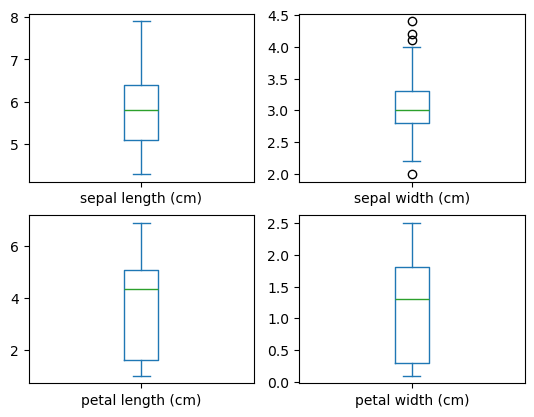

In [54]:
# 3.4.1 单变量图表
dataset.plot(kind='box',subplots=True,layout=(2,2),sharex=False)
pyplot.show()

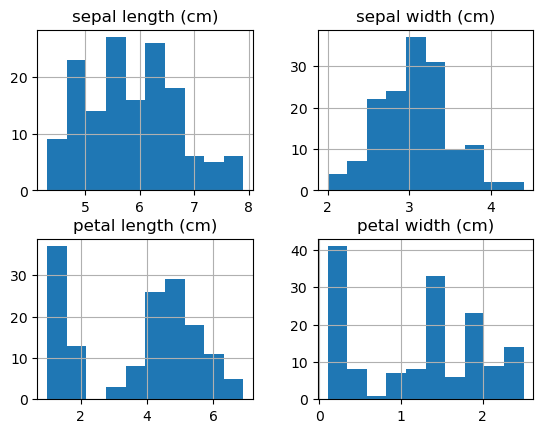

In [55]:
# 直方图
dataset.hist()
pyplot.show()

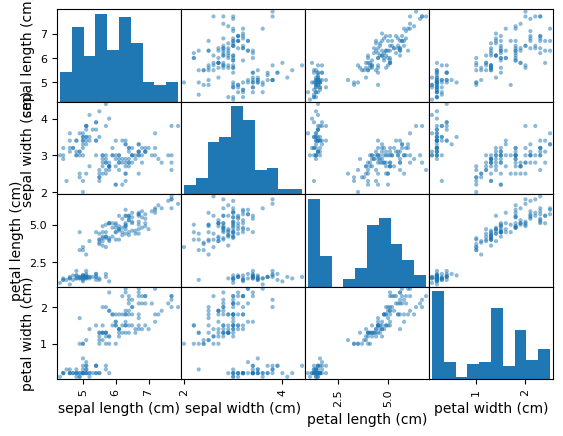

In [56]:
# 3.4.2 多变量图表
# 散点矩阵图
scatter_matrix(dataset)
pyplot.show()

In [57]:
# 3.5.1 分离出评估数据集
array=dataset.values
X=array[:,0:4]
Y=array[:,4]
validation_size=0.2
seed=7
X_train,X_validation,Y_train,Y_validation=train_test_split(X,Y,test_size=validation_size,random_state=seed)

In [58]:
# 算法审查
models={}
models['LR']=LogisticRegression()
models['LDA']=LinearDiscriminantAnalysis()
models['KNN']=KNeighborsClassifier()
models['CART']=DecisionTreeClassifier()
models['NB']=GaussianNB()
models['SVM']=SVC()

In [64]:
# 评估算法
results=[]
for key in models:
    kfold=KFold(n_splits=10,shuffle=True,random_state=seed)
    cv_results = cross_val_score (models[key],X_train,Y_train,cv=kfold,scoring='accuracy')
    results.append(cv_results)
    print('%s:%f(%f)'%(key,cv_results.mean(),cv_results.std()))

/home/GUO_Zimeng/anaconda3/envs/LLM-learning/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/GUO_Zimeng/anaconda3/envs/LLM-learning/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://sci

LR:0.983333(0.033333)
LDA:0.975000(0.038188)
KNN:0.983333(0.033333)
CART:0.950000(0.076376)
NB:0.966667(0.040825)
SVM:0.983333(0.033333)


/tmp/ipykernel_34034/3386881632.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels (models.keys())


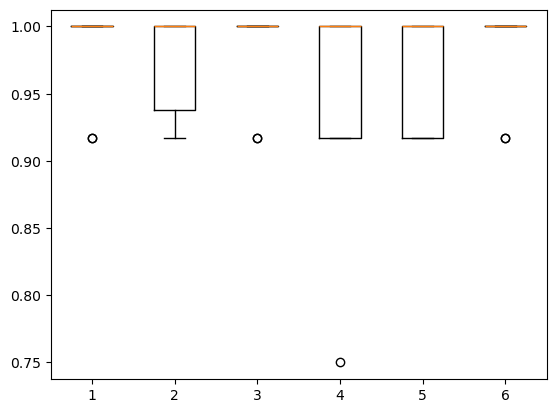

In [67]:
# 箱线图比较算法
fig=pyplot.Figure()
fig.suptitle('Algorithm Comparison')
ax=fig.add_subplot(111)
pyplot.boxplot(results)
ax.set_xticklabels (models.keys())
pyplot.show()

In [69]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# 使用评估数据集评估方法
svm=SVC()
svm.fit(X=X_train,y=Y_train)
predictions=svm.predict (X_validation)
print(accuracy_score(Y_validation,predictions))
print(confusion_matrix(Y_validation,predictions))
print(classification_report(Y_validation,predictions))

0.8666666666666667
[[ 7  0  0]
 [ 0 10  2]
 [ 0  2  9]]
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00         7
Iris-versicolor       0.83      0.83      0.83        12
 Iris-virginica       0.82      0.82      0.82        11

       accuracy                           0.87        30
      macro avg       0.88      0.88      0.88        30
   weighted avg       0.87      0.87      0.87        30

